# UNSW-NB15 Intrusion Detection System (IDS): Model Evaluation

## Overview
This notebook evaluates trained Intrusion Detection System (IDS) models using the pre-split **UNSW-NB15** dataset from `datasets/UNSW-NB15_splited/`:
- Loads the trained model and feature encoder from the model registry (`models/IDS/adaboost/{timestamp}/`).
- Directly loads the pre-split **15% Holdout Test Set** (`holdout.csv`, $N = 38,651$) without manual re-splitting.
- Computes comprehensive binary classification metrics including **Intrusion Detection Capability ($C_{ID}$)**, Accuracy, Detection Rate, Precision, Specificity, FAR, and F1-Scores.
- Generates a focused Confusion Matrix visualization with raw counts and normalized proportions.
- Evaluates per-attack category detection rate across all 9 malicious classes.
- Analyzes feature importances and benchmarks against the 15% Testing / Validation split (`test.csv`).

In [1]:
import os
import json
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Evaluation environment initialized successfully.")

Evaluation environment initialized successfully.


## 1. Load Trained Model & Preprocessing Artifacts

Locate and load the latest trained AdaBoost classifier and its `OrdinalEncoder` from `models/IDS/adaboost/`.

In [2]:
# Locate models directory
base_dir = Path.cwd()
possible_models_dirs = [
    base_dir / '../../models',
    base_dir / 'models',
    Path(r'd:/Swinburne Courses/Project A/models')
]
models_root = next((d.resolve() for d in possible_models_dirs if d.resolve().exists()), None)
if models_root is None:
    raise FileNotFoundError("Could not locate models directory.")

adaboost_dir = models_root / 'IDS' / 'adaboost'
if not adaboost_dir.exists():
    raise FileNotFoundError(f"No AdaBoost models found in: {adaboost_dir}")

# Identify the latest trained model timestamp directory
timestamp_dirs = sorted([d for d in adaboost_dir.iterdir() if d.is_dir()], key=lambda d: d.name)
if not timestamp_dirs:
    raise FileNotFoundError(f"No timestamped model runs found inside: {adaboost_dir}")

latest_model_dir = timestamp_dirs[-1]
print(f"Loading model run: {latest_model_dir.name}")
print(f"Model directory: {latest_model_dir.resolve()}")

# Load model, encoder, and metadata
with open(latest_model_dir / "adaboost_model.pkl", "rb") as f:
    clf = pickle.load(f)

with open(latest_model_dir / "ordinal_encoder.pkl", "rb") as f:
    encoder = pickle.load(f)

with open(latest_model_dir / "metadata.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(f"\nModel loaded successfully: {clf}")
print(f"Trained with {metadata.get('hyperparameters', {}).get('n_estimators')} estimators on {metadata.get('training_samples'):,} samples.")

Loading model run: 2026-09-28_16-21-01
Model directory: D:\Swinburne Courses\Project A\models\IDS\adaboost\2026-09-28_16-21-01



Model loaded successfully: AdaBoostClassifier(random_state=42)
Trained with 50 estimators on 180,371 samples.


## 2. Load Pre-Split Datasets from `UNSW-NB15_splited`

Directly load the pre-split holdout test set (`holdout.csv`) and testing/validation set (`test.csv`) without manual re-splitting.

In [3]:
# Resolve datasets/UNSW-NB15_splited directory
possible_data_dirs = [
    base_dir / '../../datasets/UNSW-NB15_splited',
    base_dir / 'datasets/UNSW-NB15_splited',
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15_splited')
]
splited_dir = next((d.resolve() for d in possible_data_dirs if d.resolve().exists()), None)
if splited_dir is None:
    raise FileNotFoundError("Could not locate datasets/UNSW-NB15_splited directory.")

print(f"Loading pre-split data from: {splited_dir}")
test_df = pd.read_csv(splited_dir / 'test.csv')
holdout_df = pd.read_csv(splited_dir / 'holdout.csv')

feature_cols = [c for c in holdout_df.columns if c not in ['label', 'attack_cat']]
cat_cols = ['proto', 'service', 'state']

X_holdout = holdout_df[feature_cols].copy()
y_holdout_bin = holdout_df['label']
y_holdout_multi = holdout_df['attack_cat']

X_test = test_df[feature_cols].copy()
y_test_bin = test_df['label']

# Encode categorical variables using the loaded encoder
X_holdout_enc = X_holdout.copy()
X_holdout_enc[cat_cols] = encoder.transform(X_holdout[cat_cols])

X_test_enc = X_test.copy()
X_test_enc[cat_cols] = encoder.transform(X_test[cat_cols])

print(f"Holdout Test Set samples:          {len(X_holdout_enc):,} rows x {X_holdout_enc.shape[1]} features")
print(f"Testing / Validation Set samples:  {len(X_test_enc):,} rows")

Loading pre-split data from: D:\Swinburne Courses\Project A\datasets\UNSW-NB15_splited


Holdout Test Set samples:          38,651 rows x 52 features
Testing / Validation Set samples:  38,651 rows


## 3. Information-Theoretic Intrusion Detection Capability ($C_{ID}$) & Core Evaluation Metrics

### Intrusion Detection Capability ($C_{ID}$)
Proposed by Gu et al. (2006) and evaluated in benchmark literature (*Kumar, 2014*), $C_{ID}$ is a single unified, information-theoretic objective metric that incorporates the base intrusion rate ($B$), true positive rate ($TPR$), and false positive rate ($FPR$):

$$C_{ID} = \frac{I(X; Y)}{H(X)} = \frac{H(X) - H(X|Y)}{H(X)}$$

Where:
- $X \in \{0, 1\}$ is the input ground truth (0 = Normal, 1 = Attack), with attack base rate $B = P(X = 1)$.
- $Y \in \{0, 1\}$ is the IDS decision (0 = Normal, 1 = Attack).
- $H(X) = -B \log_2(B) - (1 - B) \log_2(1 - B)$ is the prior entropy (uncertainty) of the input.
- $H(X|Y) = P(Y=1)H(X|Y=1) + P(Y=0)H(X|Y=0)$ is the conditional entropy remaining after observing the IDS predictions.
- $I(X; Y) = H(X) - H(X|Y)$ is the mutual information shared between input events and detection output.
- $C_{ID} \in [0, 1]$ represents the fraction of uncertainty eliminated by the detector ($C_{ID} = 1$ is ideal, $0$ indicates no capability).

In [4]:
def compute_cid(y_true, y_pred):
    """
    Compute Intrusion Detection Capability (CID) as formulated by Gu et al. (2006).
    
    CID = I(X; Y) / H(X) = (H(X) - H(X|Y)) / H(X)
    """
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = tn + fp + fn + tp
    
    # Attack base rate B = P(X = 1)
    b = (tp + fn) / total
    p_norm = (tn + fp) / total
    
    # Prior entropy H(X)
    if b == 0 or b == 1:
        h_x = 0.0
    else:
        h_x = - (b * np.log2(b) + p_norm * np.log2(p_norm))
        
    # Marginal prediction probabilities P(Y=1) and P(Y=0)
    p_y1 = (tp + fp) / total
    p_y0 = (tn + fn) / total
    
    # Conditional probabilities PPV and NPV
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    
    # Conditional entropy H(X | Y=1)
    if 0 < ppv < 1:
        h_x_given_y1 = - (ppv * np.log2(ppv) + (1.0 - ppv) * np.log2(1.0 - ppv))
    else:
        h_x_given_y1 = 0.0
        
    # Conditional entropy H(X | Y=0)
    if 0 < npv < 1:
        h_x_given_y0 = - (npv * np.log2(npv) + (1.0 - npv) * np.log2(1.0 - npv))
    else:
        h_x_given_y0 = 0.0
        
    # Total conditional entropy H(X | Y)
    h_x_given_y = p_y1 * h_x_given_y1 + p_y0 * h_x_given_y0
    
    # Mutual Information I(X; Y)
    i_xy = h_x - h_x_given_y
    
    # Normalized CID
    cid = (i_xy / h_x) if h_x > 0 else 0.0
    
    return {
        'CID': cid,
        'H_X': h_x,
        'H_X_given_Y': h_x_given_y,
        'I_XY': i_xy,
        'Base_Rate_B': b,
        'PPV': ppv,
        'NPV': npv
    }

# Run inference on Holdout Test Set
t_start = time.time()
y_test_pred = clf.predict(X_holdout_enc)
t_infer = time.time() - t_start

# Compute binary metrics
cm = confusion_matrix(y_holdout_bin, y_test_pred)
tn, fp, fn, tp = cm.ravel()

acc = accuracy_score(y_holdout_bin, y_test_pred)
prec = precision_score(y_holdout_bin, y_test_pred)
rec = recall_score(y_holdout_bin, y_test_pred)
spec = tn / (tn + fp)
far = fp / (fp + tn)
f1 = f1_score(y_holdout_bin, y_test_pred)
f1_macro = f1_score(y_holdout_bin, y_test_pred, average='macro')
f1_weighted = f1_score(y_holdout_bin, y_test_pred, average='weighted')

cid_res = compute_cid(y_holdout_bin, y_test_pred)

metrics_summary = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Intrusion Detection Capability (CID)',
        'Mutual Information I(X; Y)',
        'Prior Entropy H(X)',
        'Conditional Entropy H(X|Y)',
        'Detection Rate / Recall (Attack)',
        'Precision (Attack)',
        'Specificity (Normal)',
        'False Alarm Rate (FAR / FPR)',
        'F1-Score (Attack)',
        'F1-Score (Macro Avg)',
        'F1-Score (Weighted Avg)',
        'Inference Latency (Total)',
        'Inference Throughput (samples/sec)'
    ],
    'Value': [
        f"{acc * 100:.2f}%",
        f"{cid_res['CID']:.4f} ({cid_res['CID']*100:.2f}%)",
        f"{cid_res['I_XY']:.4f} bits",
        f"{cid_res['H_X']:.4f} bits",
        f"{cid_res['H_X_given_Y']:.4f} bits",
        f"{rec * 100:.2f}%",
        f"{prec * 100:.2f}%",
        f"{spec * 100:.2f}%",
        f"{far * 100:.2f}%",
        f"{f1:.4f}",
        f"{f1_macro:.4f}",
        f"{f1_weighted:.4f}",
        f"{t_infer:.3f} s",
        f"{len(X_holdout_enc) / t_infer:,.0f}"
    ]
})

print("=== Holdout Test Set Evaluation Summary ===")
display(metrics_summary)

print("\n=== Detailed Classification Report ===")
print(classification_report(y_holdout_bin, y_test_pred, target_names=['Normal (0)', 'Attack (1)'], digits=4))

=== Holdout Test Set Evaluation Summary ===


,Metric,Value
0,Accuracy,91.15%
1,Intrusion Detection Capability (CID),0.5435 (54.35%)
2,Mutual Information I(X; Y),0.5128 bits
3,Prior Entropy H(X),0.9434 bits
4,Conditional Entropy H(X|Y),0.4307 bits
5,Detection Rate / Recall (Attack),94.51%
6,Precision (Attack),91.87%
7,Specificity (Normal),85.18%
8,False Alarm Rate (FAR / FPR),14.82%
9,F1-Score (Attack),0.9317



=== Detailed Classification Report ===
              precision    recall  f1-score   support

  Normal (0)     0.8976    0.8518    0.8741     13950
  Attack (1)     0.9187    0.9451    0.9317     24701

    accuracy                         0.9115     38651
   macro avg     0.9082    0.8985    0.9029     38651
weighted avg     0.9111    0.9115    0.9109     38651



## 4. Visual Diagnostics: Confusion Matrix Heatmap

Examining the error distribution, true positives, true negatives, and false alarms on the holdout test set.

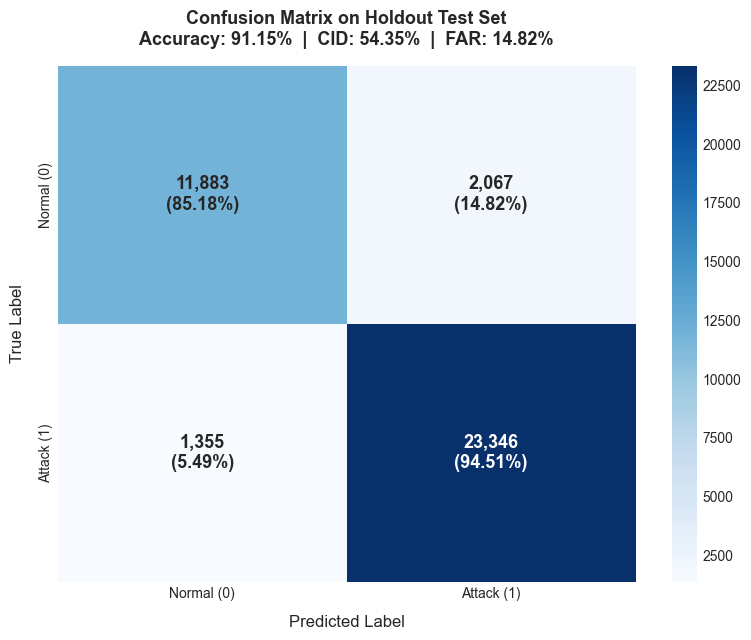

In [5]:
fig, ax = plt.subplots(figsize=(8, 6.5))

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot = [
    [f"{tn:,}\n({cm_norm[0,0]*100:.2f}%)", f"{fp:,}\n({cm_norm[0,1]*100:.2f}%)"],
    [f"{fn:,}\n({cm_norm[1,0]*100:.2f}%)", f"{tp:,}\n({cm_norm[1,1]*100:.2f}%)"]
]

sns.heatmap(
    cm,
    annot=annot,
    fmt='',
    cmap='Blues',
    ax=ax,
    cbar=True,
    xticklabels=['Normal (0)', 'Attack (1)'],
    yticklabels=['Normal (0)', 'Attack (1)'],
    annot_kws={'fontsize': 13, 'fontweight': 'bold'}
)

ax.set_title(
    f'Confusion Matrix on Holdout Test Set\nAccuracy: {acc*100:.2f}%  |  CID: {cid_res["CID"]*100:.2f}%  |  FAR: {far*100:.2f}%',
    fontweight='bold',
    fontsize=13,
    pad=15
)
ax.set_xlabel('Predicted Label', fontsize=12, labelpad=10)
ax.set_ylabel('True Label', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

## 5. Per-Attack Category Performance Breakdown

Evaluating detection rate (recall) across each of the 9 specific attack categories in the UNSW-NB15 holdout test set.

=== Breakdown by Attack Category on Holdout Test Set ===


,Category,Traffic Type,Support,Correctly Classified,Missed,Detection / Accuracy (%)
0,Normal,Normal,"13,950","11,883","2,067",85.18%
1,Generic,Attack,"8,831","8,824",7,99.92%
2,Exploits,Attack,"6,679","6,588",91,98.64%
3,Fuzzers,Attack,"3,637","2,468","1,169",67.86%
4,DoS,Attack,"2,453","2,414",39,98.41%
5,Reconnaissance,Attack,"2,098","2,089",9,99.57%
6,Analysis,Attack,401,377,24,94.01%
7,Backdoor,Attack,349,338,11,96.85%
8,Shellcode,Attack,227,222,5,97.80%
9,Worms,Attack,26,26,0,100.00%


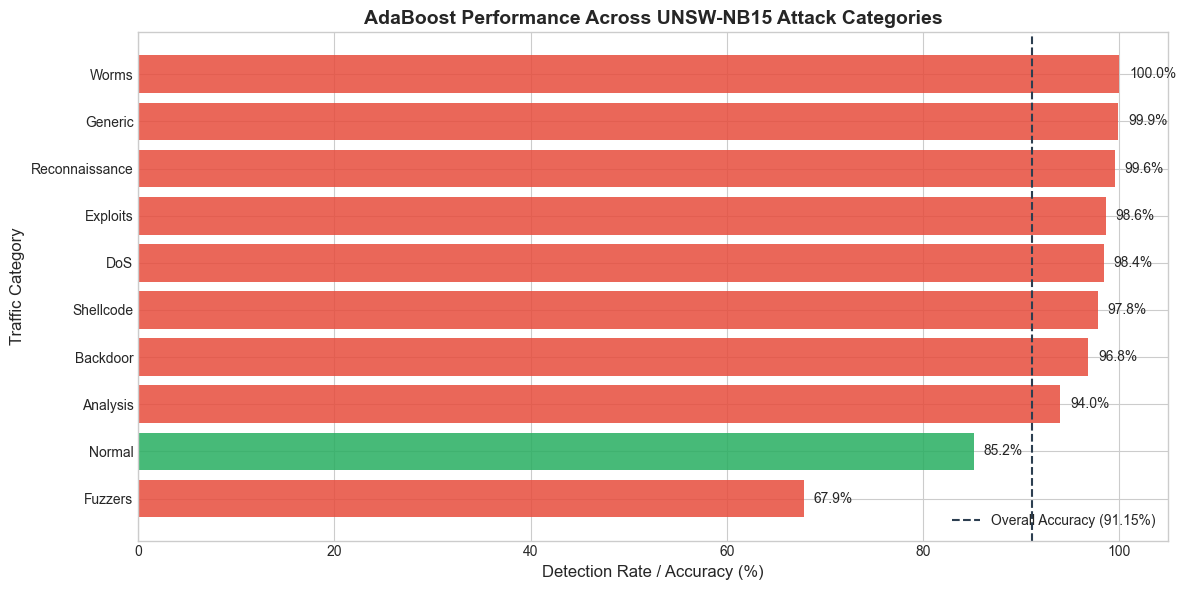

In [6]:
# Per-attack category performance assessment
holdout_analysis = holdout_df[['attack_cat', 'label']].copy()
holdout_analysis['predicted_label'] = y_test_pred

cat_rows = []
for cat, group in holdout_analysis.groupby('attack_cat'):
    total_count = len(group)
    if cat == 'Normal':
        correct_count = (group['predicted_label'] == 0).sum()
        metric_title = 'Specificity (Normal)'
    else:
        correct_count = (group['predicted_label'] == 1).sum()
        metric_title = 'Detection Rate (Recall)'
    rate_pct = (correct_count / total_count) * 100
    cat_rows.append({
        'Category': cat,
        'Traffic Type': 'Normal' if cat == 'Normal' else 'Attack',
        'Support': total_count,
        'Correctly Classified': correct_count,
        'Missed': total_count - correct_count,
        'Detection / Accuracy (%)': rate_pct
    })

cat_perf_df = pd.DataFrame(cat_rows).sort_values(by='Support', ascending=False).reset_index(drop=True)

print("=== Breakdown by Attack Category on Holdout Test Set ===")
display(cat_perf_df.style.format({
    'Support': '{:,}',
    'Correctly Classified': '{:,}',
    'Missed': '{:,}',
    'Detection / Accuracy (%)': '{:.2f}%'
}))

# Plot: Detection rate across attack categories
plot_cat = cat_perf_df.sort_values(by='Detection / Accuracy (%)', ascending=True)
colors = ['#27ae60' if t == 'Normal' else '#e74c3c' for t in plot_cat['Traffic Type']]

plt.figure(figsize=(12, 6))
bars = plt.barh(plot_cat['Category'], plot_cat['Detection / Accuracy (%)'], color=colors, alpha=0.85)
plt.axvline(x=acc*100, color='#2c3e50', linestyle='--', lw=1.5, label=f'Overall Accuracy ({acc*100:.2f}%)')
plt.xlabel('Detection Rate / Accuracy (%)', fontsize=12)
plt.ylabel('Traffic Category', fontsize=12)
plt.title('AdaBoost Performance Across UNSW-NB15 Attack Categories', fontweight='bold', fontsize=14)
plt.xlim(0, 105)
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=10)

plt.tight_layout()
plt.show()

## 6. Feature Importance Analysis

Examining the top 15 features by AdaBoost Gini importance.

=== Top 15 Most Informative Features (AdaBoost Importance) ===


,Feature,Importance
0,sttl,0.206852
1,ct_state_ttl,0.161875
2,proto,0.146095
3,ct_dst_sport_ltm,0.116310
4,smean,0.063156
5,swin,0.047318
6,ct_srv_dst,0.046118
7,log_dbytes,0.041329
8,service,0.033414
9,dbytes,0.028775


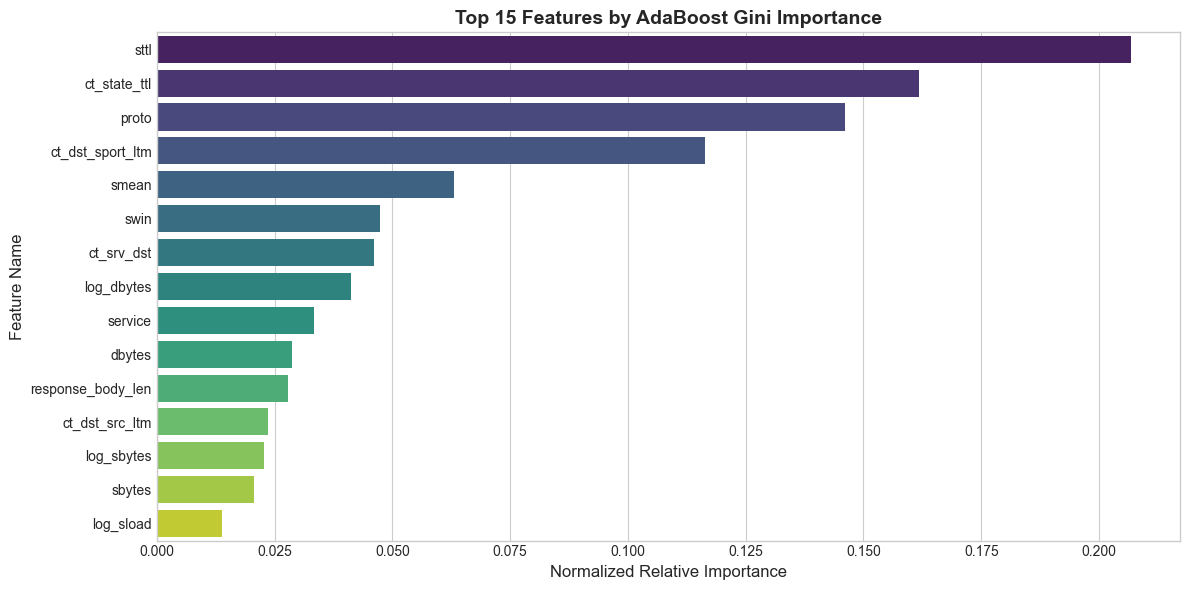

In [7]:
importances = clf.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("=== Top 15 Most Informative Features (AdaBoost Importance) ===")
display(feat_imp_df.head(15))

# Plot top 15 features
plt.figure(figsize=(12, 6))
sns.barplot(
    data=feat_imp_df.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Features by AdaBoost Gini Importance', fontweight='bold', fontsize=14)
plt.xlabel('Normalized Relative Importance', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

## 7. Testing / Validation Set vs. Holdout Set Benchmark Comparison

Comparing performance across the 15% Testing / Validation split (`test.csv`) and the 15% Holdout Test split (`holdout.csv`) to verify consistency.

In [8]:
y_val_pred = clf.predict(X_test_enc)

val_acc = accuracy_score(y_test_bin, y_val_pred)
val_f1 = f1_score(y_test_bin, y_val_pred)
val_cid = compute_cid(y_test_bin, y_val_pred)

split_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Intrusion Detection Capability (CID)', 'F1-Score (Attack)'],
    'Testing / Validation Split (15%)': [f"{val_acc*100:.2f}%", f"{val_cid['CID']:.4f} ({val_cid['CID']*100:.2f}%)", f"{val_f1:.4f}"],
    'Holdout Test Split (15%)': [f"{acc*100:.2f}%", f"{cid_res['CID']:.4f} ({cid_res['CID']*100:.2f}%)", f"{f1:.4f}"]
})

print("=== Testing / Validation vs Holdout Test Split Comparison ===")
display(split_comparison)

=== Testing / Validation vs Holdout Test Split Comparison ===


,Metric,Testing / Validation Split (15%),Holdout Test Split (15%)
0,Accuracy,91.04%,91.15%
1,Intrusion Detection Capability (CID),0.5401 (54.01%),0.5435 (54.35%)
2,F1-Score (Attack),0.9309,0.9317
